# XAUUSD H1 — N-Method Strategy Backtest

This notebook applies the **same rule definitions and numeric parameter values** used in the earlier XAUUSD D1 research to hourly OHLCV data.

It evaluates three rule-based patterns:

1. **Bullish N:** swing low (P1) → swing high (P2) → higher swing low (P3); buy stop above P2; stop below P3.
2. **Bearish N:** swing high (P1) → swing low (P2) → lower swing high (P3); sell stop below P2; stop above P3.
3. **Ranging N:** two similar highs and two similar lows; place opposing breakout orders with one-cancels-the-other (OCO) logic.

The take-profit is fixed at **2R**. This is an exploratory historical backtest, not a validated trading system.

> **Timeframe interpretation:** the numeric settings are kept identical, not rescaled. On H1, a 3-bar pivot confirmation means 3 hourly bars on each side, a 20-bar pending-order expiry means 20 H1 bars, and ATR(14) is based on 14 H1 bars. These do not represent the same calendar duration as the D1 settings.

## Rule interpretation caveat

This is an operational research implementation, not a verified reproduction of a proprietary Traders Family rulebook. Stop placement is based on general chart-structure guidance: beyond P3 for swing structures and beyond the opposite range boundary for range breakouts.

In [1]:
from __future__ import annotations

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from numpy.lib.stride_tricks import sliding_window_view

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = PROJECT_ROOT / "data" / "XAUUSD_H1.csv"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Same numeric settings as the D1 baseline. All bar-based settings are now H1 bars.
LEFT = 3
RIGHT = 3
ATR_PERIOD = 14
RR = 2.0
ENTRY_BUFFER_ATR = 0.05
SL_BUFFER_ATR = 0.05
RANGE_TOLERANCE_ATR = 0.50
EXPIRY_BARS = 20
ONE_POSITION_AT_A_TIME = True

In [2]:
# Load the headerless OHLCV file: Date, Open, High, Low, Close, Volume.
raw = pd.read_csv(DATA_PATH, header=None)
if raw.shape[1] < 5:
    raise ValueError("CSV must contain Date, Open, High, Low, and Close columns.")

column_names = ["Date", "Open", "High", "Low", "Close"]
if raw.shape[1] >= 6:
    column_names.append("Volume")
raw = raw.iloc[:, :len(column_names)].copy()
raw.columns = column_names
raw["Date"] = pd.to_datetime(raw["Date"], errors="coerce")
for col in ["Open", "High", "Low", "Close"]:
    raw[col] = pd.to_numeric(raw[col], errors="coerce")
if "Volume" in raw:
    raw["Volume"] = pd.to_numeric(raw["Volume"], errors="coerce")

data = (raw.dropna(subset=["Date", "Open", "High", "Low", "Close"])
            .sort_values("Date").drop_duplicates("Date").set_index("Date"))

invalid = (data["High"] < data[["Open", "Close", "Low"]].max(axis=1)) | (
    data["Low"] > data[["Open", "Close", "High"]].min(axis=1)
)
if invalid.any():
    raise ValueError(f"Found {invalid.sum()} invalid OHLC bars.")

print(f"Rows: {len(data):,}")
print(f"Period: {data.index.min()} to {data.index.max()}")
display(data.head())

Rows: 100,000
Period: 2010-02-22 18:00:00 to 2026-11-12 06:00:00


,Open,High,Low,Close,Volume
Date,,,,,
2010-02-22 18:00:00,1115.289,1115.616,1111.221,1112.457,60
2010-02-22 19:00:00,1112.401,1115.563,1112.341,1114.980,60
2010-02-22 20:00:00,1114.921,1116.300,1112.514,1113.146,60
2010-02-22 21:00:00,1113.056,1114.256,1112.544,1113.645,55
2010-02-22 22:00:00,1113.729,1114.142,1112.397,1112.819,38


In [3]:
# Calculate ATR(14) using the same 14-bar simple rolling mean of True Range.
prev_close = data["Close"].shift(1)
true_range = pd.concat([
    data["High"] - data["Low"],
    (data["High"] - prev_close).abs(),
    (data["Low"] - prev_close).abs(),
], axis=1).max(axis=1)
data["ATR"] = true_range.rolling(ATR_PERIOD, min_periods=ATR_PERIOD).mean()


def confirmed_pivots(frame: pd.DataFrame, left: int = LEFT, right: int = RIGHT) -> list[dict]:
    """Return pivots only at their confirmation bar; never use an unconfirmed pivot."""
    highs = frame["High"].to_numpy()
    lows = frame["Low"].to_numpy()
    width = left + right + 1
    high_windows = sliding_window_view(highs, width)
    low_windows = sliding_window_view(lows, width)
    center_high = high_windows[:, left]
    center_low = low_windows[:, left]

    # Match the original tie rule: the center is the extreme and no equal extreme
    # occurs to its right within the pivot window.
    is_high = (center_high >= high_windows.max(axis=1)) & ~(
        high_windows[:, left + 1:] == center_high[:, None]
    ).any(axis=1)
    is_low = (center_low <= low_windows.min(axis=1)) & ~(
        low_windows[:, left + 1:] == center_low[:, None]
    ).any(axis=1)

    points = []
    for offset in np.flatnonzero(is_high | is_low):
        pivot_i = int(offset + left)
        confirm_i = pivot_i + right
        if is_high[offset]:
            points.append({"type": "H", "pivot_i": pivot_i, "confirm_i": confirm_i,
                           "price": float(highs[pivot_i]), "date": frame.index[pivot_i]})
        if is_low[offset]:
            points.append({"type": "L", "pivot_i": pivot_i, "confirm_i": confirm_i,
                           "price": float(lows[pivot_i]), "date": frame.index[pivot_i]})
    points.sort(key=lambda p: (p["confirm_i"], p["pivot_i"]))
    return points

pivots = confirmed_pivots(data)
print(f"Confirmed pivots: {len(pivots):,}")

Confirmed pivots: 19,846


In [4]:
def backtest_setups(frame: pd.DataFrame, setups: list[dict]) -> pd.DataFrame:
    """Backtest pending stop orders with gap-aware fills and conservative OHLC rules.

    Entry orders are active from the bar after setup confirmation and expire after
    EXPIRY_BARS. Each strategy is evaluated independently with one position open
    at a time. For OCO orders, a same-bar trigger on both sides is marked ambiguous.
    If SL and TP are both touched in one bar, SL is assumed first.
    """
    n = len(frame)
    idx = frame.index
    open_ = frame["Open"].to_numpy()
    high = frame["High"].to_numpy()
    low = frame["Low"].to_numpy()
    close = frame["Close"].to_numpy()
    results = []
    busy_until = -1

    for setup in sorted(setups, key=lambda item: item["signal_i"]):
        signal_i = int(setup["signal_i"])
        if signal_i + 1 >= n:
            continue
        if ONE_POSITION_AT_A_TIME and signal_i <= busy_until:
            continue

        first_active = signal_i + 1
        last_active = min(n - 1, first_active + EXPIRY_BARS - 1)
        valid_order_hits = []

        # Find the first valid trigger for each pending order. A malformed gap fill
        # is skipped and the order remains active, matching the original event logic.
        for order in setup["orders"]:
            side = order["side"]
            entry_level = float(order["entry"])
            stop_level = float(order["sl"])
            touched = (high[first_active:last_active + 1] >= entry_level) if side == "long" else (
                low[first_active:last_active + 1] <= entry_level
            )
            for offset in np.flatnonzero(touched):
                entry_i = first_active + int(offset)
                fill = max(entry_level, float(open_[entry_i])) if side == "long" else min(
                    entry_level, float(open_[entry_i])
                )
                if (side == "long" and stop_level >= fill) or (side == "short" and stop_level <= fill):
                    continue
                risk = abs(fill - stop_level)
                target = fill + RR * risk if side == "long" else fill - RR * risk
                valid_order_hits.append({"i": entry_i, "side": side, "entry": fill,
                                         "sl": stop_level, "tp": target, "risk": risk})
                break

        if not valid_order_hits:
            continue

        earliest_i = min(hit["i"] for hit in valid_order_hits)
        hits_at_earliest = [hit for hit in valid_order_hits if hit["i"] == earliest_i]
        if len(hits_at_earliest) > 1:
            results.append({"setup": setup["setup_type"], "side": "ambiguous",
                            "signal_date": idx[signal_i], "entry_date": idx[earliest_i],
                            "entry": np.nan, "sl": np.nan, "tp": np.nan,
                            "exit_date": idx[earliest_i], "exit": np.nan,
                            "result": "AMBIGUOUS_BOTH_SIDES", "R": 0.0,
                            "bars_held": 0, "pattern": setup.get("pattern", "")})
            busy_until = earliest_i
            continue

        order = hits_at_earliest[0]
        side, entry, stop_level, target, risk = (
            order["side"], order["entry"], order["sl"], order["tp"], order["risk"]
        )
        start = earliest_i
        if side == "long":
            stop_hits = low[start:] <= stop_level
            target_hits = high[start:] >= target
        else:
            stop_hits = high[start:] >= stop_level
            target_hits = low[start:] <= target
        any_exit = stop_hits | target_hits
        exit_offsets = np.flatnonzero(any_exit)

        if len(exit_offsets):
            exit_i = start + int(exit_offsets[0])
            # Conservative same-bar rule: stop-loss takes precedence over take-profit.
            if stop_hits[exit_offsets[0]]:
                if side == "long":
                    exit_price = min(stop_level, float(open_[exit_i])) if open_[exit_i] < stop_level else stop_level
                else:
                    exit_price = max(stop_level, float(open_[exit_i])) if open_[exit_i] > stop_level else stop_level
                result = "SL"
            else:
                if side == "long":
                    exit_price = max(target, float(open_[exit_i])) if open_[exit_i] > target else target
                else:
                    exit_price = min(target, float(open_[exit_i])) if open_[exit_i] < target else target
                result = "TP"
        else:
            exit_i = n - 1
            exit_price = float(close[-1])
            result = "OPEN_AT_END"

        pnl_points = exit_price - entry if side == "long" else entry - exit_price
        r_multiple = pnl_points / risk if risk > 0 else np.nan
        results.append({"setup": setup["setup_type"], "side": side,
                        "signal_date": idx[signal_i], "entry_date": idx[earliest_i],
                        "entry": entry, "sl": stop_level, "tp": target,
                        "exit_date": idx[exit_i], "exit": exit_price,
                        "result": result, "R": r_multiple,
                        "bars_held": exit_i - earliest_i + 1,
                        "pattern": setup.get("pattern", "")})
        busy_until = exit_i

    return pd.DataFrame(results)


def summarize(trades: pd.DataFrame) -> pd.Series:
    if trades.empty:
        return pd.Series({"Trades": 0, "Win rate %": np.nan, "Net R": 0.0,
                          "Profit factor (R)": np.nan, "Avg R": np.nan,
                          "Max consecutive losses": 0})
    valid = trades[trades["result"].isin(["TP", "SL", "OPEN_AT_END"])].copy()
    wins = valid[valid["R"] > 0]
    losses = valid[valid["R"] < 0]
    gross_profit = wins["R"].sum()
    gross_loss = abs(losses["R"].sum())
    closed = valid[valid["result"].isin(["TP", "SL"])]
    streak = max_streak = 0
    for is_loss in (closed["R"] < 0):
        streak = streak + 1 if is_loss else 0
        max_streak = max(max_streak, streak)
    return pd.Series({
        "Trades": len(valid),
        "Win rate %": 100 * (valid["R"] > 0).mean() if len(valid) else np.nan,
        "Net R": valid["R"].sum(),
        "Profit factor (R)": gross_profit / gross_loss if gross_loss else np.inf,
        "Avg R": valid["R"].mean() if len(valid) else np.nan,
        "Max consecutive losses": max_streak,
    })

In [5]:
# Generate Bullish N, Bearish N, and Ranging N setups from confirmed pivots.
atr = data["ATR"].to_numpy()
setups = {"bullish": [], "bearish": [], "ranging": []}

for k in range(2, len(pivots)):
    p1, p2, p3 = pivots[k - 2:k + 1]
    if [p1["type"], p2["type"], p3["type"]] != ["L", "H", "L"]:
        continue
    if not (p3["price"] > p1["price"] and p2["price"] > p1["price"]):
        continue
    signal_i = p3["confirm_i"]
    a = atr[signal_i]
    if not np.isfinite(a) or a <= 0:
        continue
    entry = p2["price"] + ENTRY_BUFFER_ATR * a
    sl = p3["price"] - SL_BUFFER_ATR * a
    if sl < entry:
        setups["bullish"].append({"signal_i": signal_i, "setup_type": "bullish",
            "orders": [{"side": "long", "entry": entry, "sl": sl}],
            "pattern": f"P1={p1['price']:.2f}; P2={p2['price']:.2f}; P3={p3['price']:.2f}"})

for k in range(2, len(pivots)):
    p1, p2, p3 = pivots[k - 2:k + 1]
    if [p1["type"], p2["type"], p3["type"]] != ["H", "L", "H"]:
        continue
    if not (p3["price"] < p1["price"] and p2["price"] < p1["price"]):
        continue
    signal_i = p3["confirm_i"]
    a = atr[signal_i]
    if not np.isfinite(a) or a <= 0:
        continue
    entry = p2["price"] - ENTRY_BUFFER_ATR * a
    sl = p3["price"] + SL_BUFFER_ATR * a
    if sl > entry:
        setups["bearish"].append({"signal_i": signal_i, "setup_type": "bearish",
            "orders": [{"side": "short", "entry": entry, "sl": sl}],
            "pattern": f"P1={p1['price']:.2f}; P2={p2['price']:.2f}; P3={p3['price']:.2f}"})

for k in range(3, len(pivots)):
    q = pivots[k - 3:k + 1]
    types = [point["type"] for point in q]
    if types not in (["H", "L", "H", "L"], ["L", "H", "L", "H"]):
        continue
    highs = [point["price"] for point in q if point["type"] == "H"]
    lows = [point["price"] for point in q if point["type"] == "L"]
    signal_i = q[-1]["confirm_i"]
    a = atr[signal_i]
    if not np.isfinite(a) or a <= 0:
        continue
    range_high, range_low = max(highs), min(lows)
    high_ok = abs(highs[1] - highs[0]) <= RANGE_TOLERANCE_ATR * a
    low_ok = abs(lows[1] - lows[0]) <= RANGE_TOLERANCE_ATR * a
    if not (high_ok and low_ok and range_high > range_low):
        continue
    setups["ranging"].append({"signal_i": signal_i, "setup_type": "ranging", "orders": [
        {"side": "long", "entry": range_high + ENTRY_BUFFER_ATR * a,
         "sl": range_low - SL_BUFFER_ATR * a},
        {"side": "short", "entry": range_low - ENTRY_BUFFER_ATR * a,
         "sl": range_high + SL_BUFFER_ATR * a}],
        "pattern": f"RangeLow={range_low:.2f}; RangeHigh={range_high:.2f}"})

print("Candidate setups:", {key: len(value) for key, value in setups.items()})

Candidate setups: {'bullish': 3135, 'bearish': 2921, 'ranging': 622}


In [6]:
# Backtest each strategy separately, as in the D1 research.
strategy_trades = {
    strategy: backtest_setups(data, setup_list)
    for strategy, setup_list in setups.items()
}
all_trades = pd.concat(strategy_trades.values(), ignore_index=True)
all_trades = all_trades.sort_values(["entry_date", "setup"], na_position="last").reset_index(drop=True)

summary = pd.DataFrame({f"{name.title()} N": summarize(strategy_trades[name])
                        for name in ["bullish", "bearish", "ranging"]}).T

display(summary.round(3))
display(all_trades.tail())

all_trades.to_csv(OUTPUT_DIR / "XAUUSD_H1_N_method_trades.csv", index=False)
summary.to_csv(OUTPUT_DIR / "XAUUSD_H1_N_method_summary.csv")
print("Saved trade-level results and summary to outputs/.")

,Trades,Win rate %,Net R,Profit factor (R),Avg R,Max consecutive losses
Bullish N,1302.0,33.564,-6.692,0.992,-0.005,15.0
Bearish N,1227.0,29.666,-156.684,0.823,-0.128,17.0
Ranging N,417.0,36.691,41.985,1.159,0.101,9.0


,setup,side,signal_date,entry_date,entry,sl,tp,exit_date,exit,result,R,bars_held,pattern
2949,bullish,long,2026-11-04 00:00:00,2026-11-04 05:00:00,3971.692479,3916.497521,4082.082393,2026-11-05 00:00:00,4082.082393,TP,2.000000,19,P1=3895.28; P2=3970.88; P3=3917.31
2950,bearish,short,2026-11-05 14:00:00,2026-11-05 15:00:00,4107.738225,4139.102775,4045.009125,2026-11-06 03:00:00,4045.009125,TP,2.000000,12,P1=4146.78; P2=4108.77; P3=4138.07
2951,bullish,long,2026-11-09 02:00:00,2026-11-09 03:00:00,4119.737000,4053.102529,4253.005943,2026-11-10 13:00:00,4053.102529,SL,-1.000000,34,P1=4027.18; P2=4078.47; P3=4054.11
2952,bullish,long,2026-11-11 04:00:00,2026-11-11 05:00:00,4053.119011,4025.675989,4108.005054,2026-11-11 14:00:00,4025.675989,SL,-1.000000,10,P1=4013.36; P2=4052.38; P3=4026.41
2953,bearish,short,2026-11-12 04:00:00,2026-11-12 06:00:00,3967.854082,4001.030918,3901.500411,2026-11-12 06:00:00,3965.600000,OPEN_AT_END,0.067941,1,P1=4066.79; P2=3968.55; P3=4000.33


Saved trade-level results and summary to outputs/.


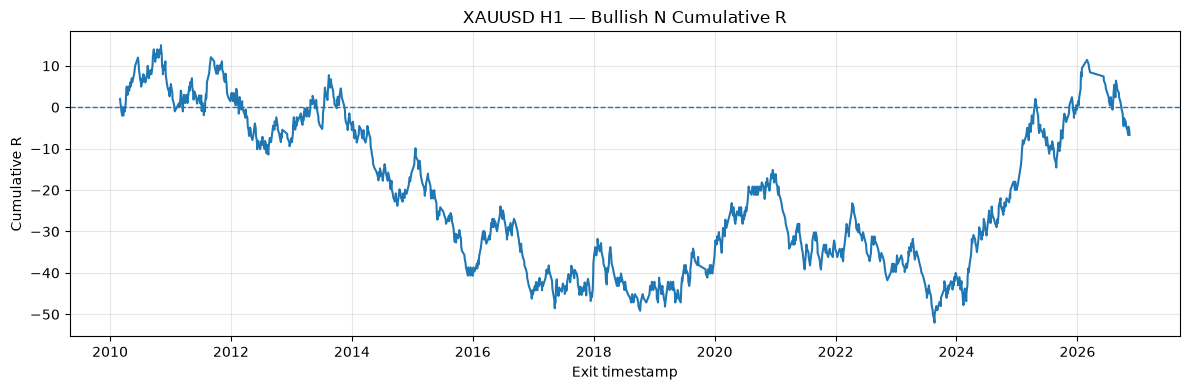

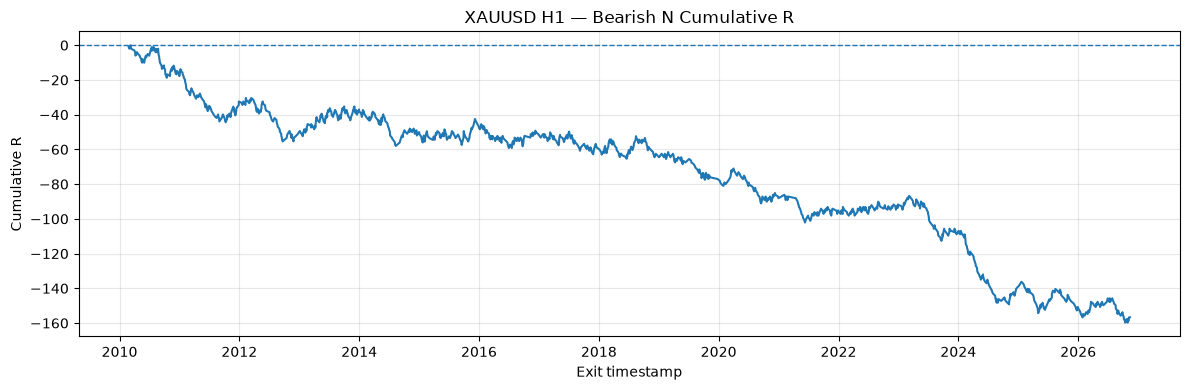

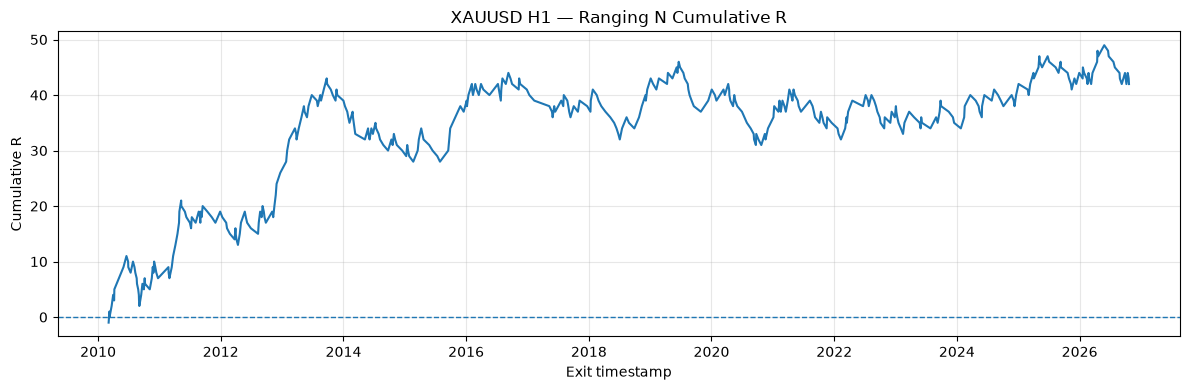

In [7]:
# Plot cumulative R by strategy.
for strategy, strategy_df in strategy_trades.items():
    valid = strategy_df[strategy_df["result"].isin(["TP", "SL", "OPEN_AT_END"])].copy()
    if valid.empty:
        continue
    valid = valid.sort_values("exit_date")
    plt.figure(figsize=(12, 4))
    plt.plot(valid["exit_date"], valid["R"].cumsum())
    plt.axhline(0, linestyle="--", linewidth=1)
    plt.title(f"XAUUSD H1 — {strategy.title()} N Cumulative R")
    plt.xlabel("Exit timestamp")
    plt.ylabel("Cumulative R")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

## Cumulative performance over time (equity-curve view)

The following chart plots cumulative trade outcomes in **R multiples** against trade exit time. It shows the path of historical strategy performance rather than only the final Net R summary.

- Each completed trade contributes its realized R multiple on its exit timestamp.
- Trades exiting at the same timestamp are aggregated before the cumulative sum is calculated.
- `OPEN_AT_END` trades are included as a final mark-to-market observation at the end of the sample; they are not realized closed trades.
- The combined line is the arithmetic sum of the three independently backtested strategy streams. It is **not** a shared-capital portfolio simulation: overlapping positions, capital allocation, margin, and portfolio-level risk limits are not enforced.
- R is a risk unit, not a currency amount or percentage return. Trading costs are not included.


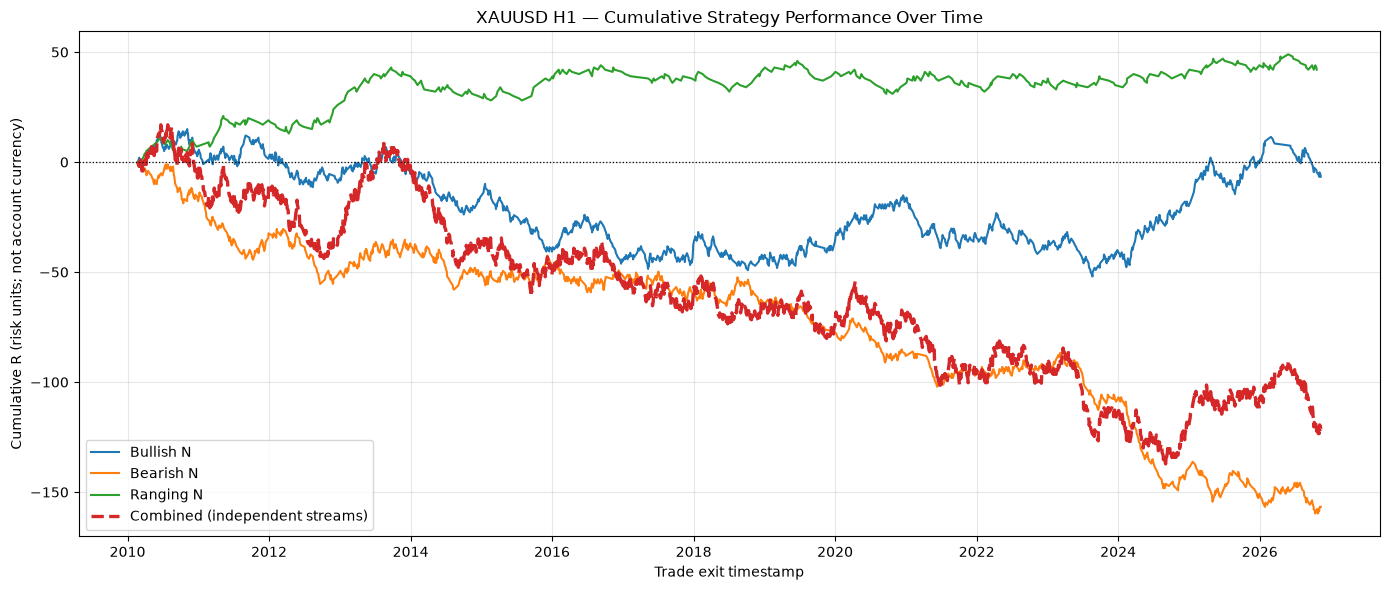

Saved cumulative R chart and time-series data to assets/ and outputs/.


In [8]:
# Plot each strategy's cumulative R and the arithmetic sum of all three streams.
# The combined line is illustrative only; the strategy variants were backtested
# independently and may overlap in time.
VALID_RESULTS = {"TP", "SL", "OPEN_AT_END"}
equity_trades = all_trades[all_trades["result"].isin(VALID_RESULTS)].copy()
equity_trades["exit_date"] = pd.to_datetime(equity_trades["exit_date"])

ASSET_DIR = PROJECT_ROOT / "assets"
ASSET_DIR.mkdir(parents=True, exist_ok=True)


def cumulative_r_curve(frame: pd.DataFrame, start_time: pd.Timestamp) -> pd.Series:
    """Aggregate R by exit timestamp, then compute cumulative R from zero."""
    if frame.empty:
        return pd.Series(dtype=float)
    increments = frame.groupby("exit_date")["R"].sum().sort_index()
    increments.loc[pd.Timestamp(start_time)] = increments.get(pd.Timestamp(start_time), 0.0)
    increments = increments.groupby(level=0).sum().sort_index()
    return increments.cumsum()


curve_rows = []
plt.figure(figsize=(14, 6))
for strategy in ["bullish", "bearish", "ranging"]:
    subset = equity_trades[equity_trades["setup"] == strategy]
    curve = cumulative_r_curve(subset, data.index.min())
    if not curve.empty:
        plt.plot(curve.index, curve.values, label=f"{strategy.title()} N", linewidth=1.5)
        curve_rows.extend({"exit_date": timestamp, "series": f"{strategy.title()} N",
                           "cumulative_R": value}
                          for timestamp, value in curve.items())

combined_curve = cumulative_r_curve(equity_trades, data.index.min())
if not combined_curve.empty:
    plt.plot(combined_curve.index, combined_curve.values, label="Combined (independent streams)",
             linewidth=2.4, linestyle="--")
    curve_rows.extend({"exit_date": timestamp, "series": "Combined (independent streams)",
                       "cumulative_R": value}
                      for timestamp, value in combined_curve.items())

plt.axhline(0, color="black", linewidth=0.9, linestyle=":")
plt.title("XAUUSD H1 — Cumulative Strategy Performance Over Time")
plt.xlabel("Trade exit timestamp")
plt.ylabel("Cumulative R (risk units; not account currency)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(ASSET_DIR / "h1_cumulative_r_by_strategy.png", dpi=160, bbox_inches="tight")
plt.show()

cumulative_curve_df = pd.DataFrame(curve_rows)
cumulative_curve_df.to_csv(OUTPUT_DIR / "XAUUSD_H1_cumulative_R_by_strategy.csv", index=False)
print("Saved cumulative R chart and time-series data to assets/ and outputs/.")


## Assumptions and limitations

1. The CSV is treated as headerless OHLCV data with timestamp, Open, High, Low, Close, and Volume columns.
2. A pivot becomes usable only after the configured `RIGHT` bars have closed. This prevents pivot look-ahead.
3. Pending stop-entry orders become active on the bar after setup confirmation and expire after `EXPIRY_BARS` H1 bars.
4. Each strategy is backtested independently with one position at a time. The three strategy streams are not constrained by a shared portfolio exposure limit.
5. Ranging N uses OCO logic. If both boundaries trigger in the same H1 bar, the case is marked ambiguous and excluded from performance statistics.
6. If stop-loss and take-profit are both touched in the same H1 bar, stop-loss is assumed first.
7. Gap-aware entry/exit fills are modeled from OHLC data, but broker spread, commission, swap, and additional slippage are not included.
8. An `OPEN_AT_END` trade is marked to the final close and is not a realized closed-trade outcome.
9. The code is a practical interpretation of a chart pattern, not a verified implementation of a proprietary N-Method rulebook.
10. These results are **historical exploratory backtest results, not a validated trading system**. They do not establish live profitability.